06 · Évaluation finale sur le test et interprétation

Étapes 10 et 11. Toutes les décisions (modèle, hyperparamètres, calibration, seuil) ont été prises dans les notebooks 03 à 05 et sont relues depuis `data/processed/decisions.json`. Le test est ouvert une seule fois.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inclusion_financiere.config import RANDOM_STATE, FIGURES, DECISIONS, COST_FP, COST_FN
from inclusion_financiere.data import load_raw, clean, split, make_cv, CAT_COLS, NUM_COLS

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

import json
import shap
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (PrecisionRecallDisplay, average_precision_score, brier_score_loss,
                             confusion_matrix, recall_score, roc_auc_score)

from inclusion_financiere.features import pipe
from inclusion_financiere.evaluate import bootstrap_ci, cout_total, expected_calibration_error

dec = json.loads(DECISIONS.read_text())
{k: dec[k] for k in ("histgb_params", "calibration", "seuil_retenu")}

{'histgb_params': {'learning_rate': 0.07373313352383347,
  'max_leaf_nodes': 7,
  'min_samples_leaf': 6,
  'l2_regularization': 7.684598675918744,
  'max_features': 0.9931252816724722,
  'max_iter': 327},
 'calibration': 'sigmoid',
 'seuil_retenu': 0.09090909090909091}

Étape 10 · Réentraîner sur tout le train, puis ouvrir le test

In [2]:
X, y = clean(load_raw())
X_train, X_test, y_train, y_test = split(X, y)

meilleur_modele = pipe(HistGradientBoostingClassifier(**dec["histgb_params"], random_state=RANDOM_STATE))
seuil_retenu = dec["seuil_retenu"]
final = CalibratedClassifierCV(meilleur_modele, method=dec["calibration"], cv=5)
final.fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= seuil_retenu).astype(int)

In [3]:
ci = lambda f: bootstrap_ci(y_test, p_test, f)
pr_ci, roc_ci = ci(average_precision_score), ci(roc_auc_score)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
n_pos, n_neg = int(y_test.sum()), int((1 - y_test).sum())
final_tab = pd.Series({
    "PR-AUC": f"{average_precision_score(y_test, p_test):.4f}  [IC 95 % : {pr_ci[0]:.4f} – {pr_ci[1]:.4f}]",
    "ROC-AUC": f"{roc_auc_score(y_test, p_test):.4f}  [IC 95 % : {roc_ci[0]:.4f} – {roc_ci[1]:.4f}]",
    "Brier": f"{brier_score_loss(y_test, p_test):.4f}",
    "ECE": f"{expected_calibration_error(y_test, p_test):.4f}",
    "Seuil retenu": f"{seuil_retenu:.4f}",
    "Matrice (TN, FP, FN, TP)": f"{tn}, {fp}, {fn}, {tp}",
    "Recall / Précision": f"{tp / (tp + fn):.3f} / {tp / (tp + fp):.3f}",
    "Coût au seuil retenu (USD)": f"{cout_total(y_test, y_pred):.1f}",
    "Coût au seuil 0,5 (USD)": f"{cout_total(y_test, (p_test >= 0.5).astype(int)):.1f}",
    "Coût « contacter tout le monde »": f"{n_neg * COST_FP:.1f}",
    "Coût « ne contacter personne »": f"{n_pos * COST_FN:.1f}",
}, name="Test (4 705 personnes)")
final_tab.to_frame()

,Test (4 705 personnes)
PR-AUC,0.5971 [IC 95 % : 0.5602 – 0.6338]
ROC-AUC,0.8753 [IC 95 % : 0.8614 – 0.8892]
Brier,0.0823
ECE,0.0117
Seuil retenu,0.0909
"Matrice (TN, FP, FN, TP)","2770, 1273, 80, 582"
Recall / Précision,0.879 / 0.314
Coût au seuil retenu (USD),1036.5
"Coût au seuil 0,5 (USD)",2109.0
Coût « contacter tout le monde »,2021.5


PR-AUC en validation croisée (hors pli, calibré) : 0.5768 (plis : 0.5779 ± 0.0276)
IC 95 % sur le test : [0.5602 ; 0.6338] -> dans l'intervalle


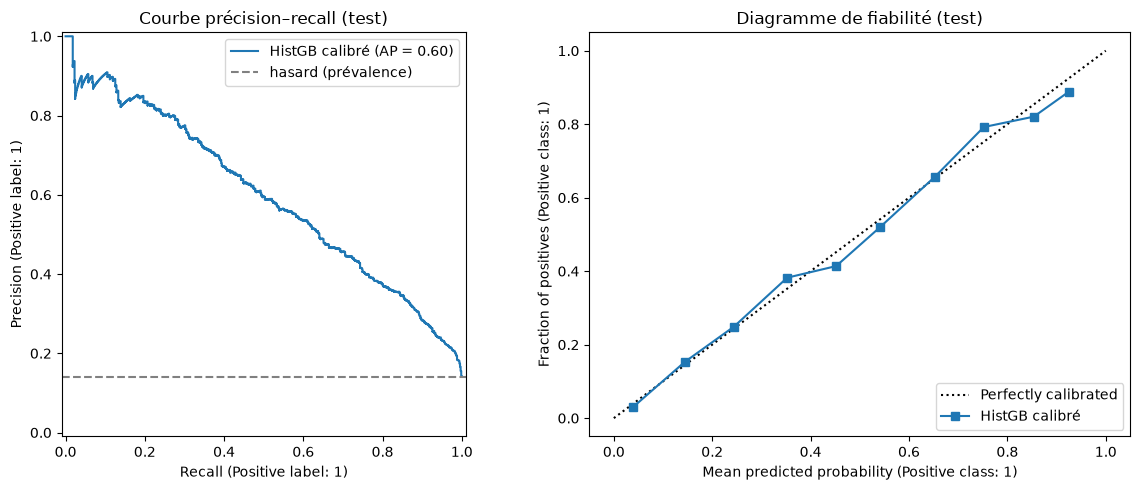

In [4]:
plis = np.array(dec["cv_pr_auc_calibre_plis"])
print(f"PR-AUC en validation croisée (hors pli, calibré) : {dec['cv_pr_auc_calibre']:.4f} "
      f"(plis : {plis.mean():.4f} ± {plis.std(ddof=1):.4f})")
print(f"IC 95 % sur le test : [{pr_ci[0]:.4f} ; {pr_ci[1]:.4f}] -> "
      f"{'dans' if pr_ci[0] <= dec['cv_pr_auc_calibre'] <= pr_ci[1] else 'HORS de'} l'intervalle")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[0], name="HistGB calibré")
axes[0].axhline(y_test.mean(), color="grey", ls="--", label="hasard (prévalence)"); axes[0].legend()
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=10, ax=axes[1], name="HistGB calibré")
axes[0].set_title("Courbe précision–recall (test)"); axes[1].set_title("Diagramme de fiabilité (test)")
plt.tight_layout(); plt.savefig(FIGURES / "06_test_pr_fiabilite.png", dpi=120); plt.show()

Q10.1 — Modèle final : HistGB réglé avec Optuna + calibration de Platt, réentraîné sur tout le train, seuil t* = 0,0909. Test : 4 705 personnes, 662 bancarisées.

| Métrique | Test |
|---|---|
| PR-AUC | 0,597 [IC 95 % : 0,560 – 0,634] |
| ROC-AUC | 0,875 [0,861 – 0,889] |
| Brier | 0,082 |
| ECE | 0,012 |
| Matrice de confusion (TN, FP, FN, TP) | 2 770 ; 1 273 ; 80 ; 582 |
| Recall / précision au seuil t* | 0,879 / 0,314 |
| Coût au seuil t* | 1 036,5 USD |
| Coût au seuil 0,5 | 2 109,0 USD |
| Contacter tout le monde / personne | 2 021,5 / 3 310,0 USD |

Le modèle trouve 88 % des bancarisés en contactant 39 % des gens, et coûte deux fois moins cher que « contacter tout le monde ».

Q10.2 — Oui. En validation croisée on avait 0,577, et sur le test on a 0,597, ce qui est dans l'intervalle [0,560 ; 0,634]. La petite différence vient du hasard. Donc pas de surapprentissage ni de fuite : on peut s'attendre à une PR-AUC entre 0,56 et 0,63 sur de nouvelles personnes de ces 4 pays.

Q10.3 — Si on change quelque chose après avoir regardé le test, le test ne mesure plus honnêtement la performance : le score devient trop optimiste. Si on le fait quand même, il faut l'écrire dans le README, donner les chiffres avant et après, et dire qu'ils sont optimistes. Ici, je n'ai rien changé après avoir ouvert le test.

Étape 11 · Interpréter le modèle final

11.1 · Importance par permutation (sur le test, colonnes d'origine)

In [5]:
pi = permutation_importance(final, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.DataFrame({"baisse PR-AUC": pi.importances_mean, "écart-type": pi.importances_std},
                    index=X_test.columns).sort_values("baisse PR-AUC", ascending=False)
perm.round(4)

,baisse PR-AUC,écart-type
education_level,0.2143,0.0100
job_type,0.1205,0.0077
country,0.0650,0.0065
cellphone_access,0.0437,0.0077
age_of_respondent,0.0393,0.0068
location_type,0.0234,0.0046
gender_of_respondent,0.0102,0.0032
relationship_with_head,0.0057,0.0024
marital_status,0.0010,0.0008
household_size,-0.0011,0.0012


Q11.1 — Les 5 variables les plus importantes : `education_level` (0,214), `job_type` (0,121), `country` (0,065), `cellphone_access` (0,044), `age_of_respondent` (0,039). Mes trois hypothèses de Q2.7 sont confirmées : éducation, emploi et téléphone. `household_size` ne sert à rien, comme mes variables en Q5.2. Le genre est 7ᵉ (0,010).

11.2 · SHAP (modèle d'arbres non calibré : la calibration est monotone)

Additivité vérifiée : True


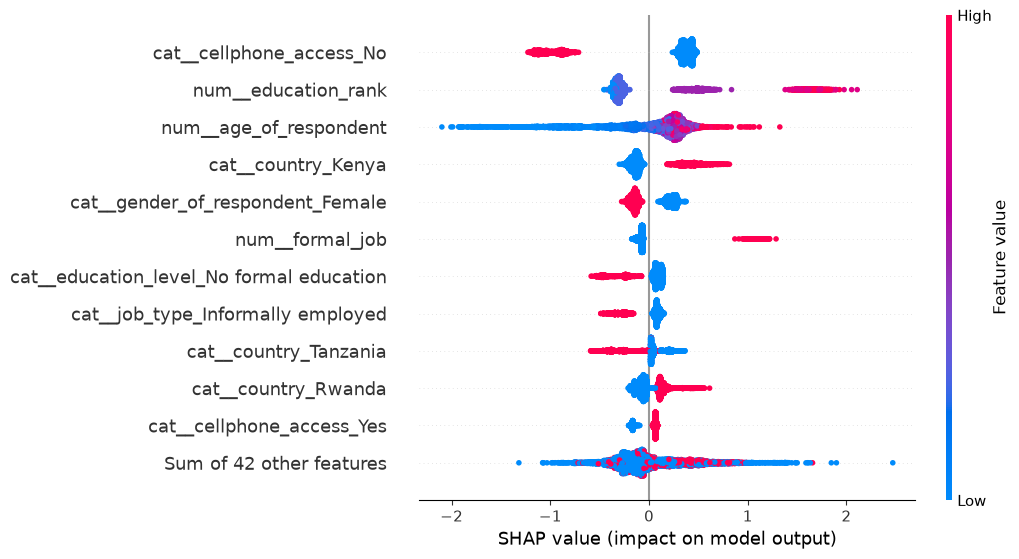

In [6]:
modele = pipe(HistGradientBoostingClassifier(**dec["histgb_params"], random_state=RANDOM_STATE))
modele.fit(X_train, y_train)
prep, hgb = modele[:-1], modele[-1]
noms = prep[-1].get_feature_names_out()
X_t = pd.DataFrame(prep.transform(X_test), columns=noms, index=X_test.index)

sv = shap.TreeExplainer(hgb)(X_t)
# Vérification : valeur de base + somme des contributions = log-odds du modèle
print("Additivité vérifiée :", np.allclose(sv.base_values[:5] + sv.values[:5].sum(1),
                                          hgb.decision_function(X_t.iloc[:5])))
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.savefig(FIGURES / "06_shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

In [7]:
# Q11.2 : agréger |SHAP| par variable d'origine
ORIGINE = {"education_rank": "education_level", "is_head": "relationship_with_head",
           "formal_job": "job_type", "age_group": "age_of_respondent",
           "is_alone": "household_size", "household_group": "household_size",
           "urban_phone": "urban_phone (location × téléphone)"}

def origine(nom):
    bloc, var = nom.split("__", 1)
    if bloc == "cat":
        var = next(c for c in sorted(ORIGINE.keys() | set(CAT_COLS), key=len, reverse=True)
                   if var.startswith(c + "_"))
    return ORIGINE.get(var, var)

abs_shap = pd.DataFrame(np.abs(sv.values), columns=noms).T
abs_shap["origine"] = [origine(c) for c in noms]
shap_agr = abs_shap.groupby("origine").sum().mean(axis=1).sort_values(ascending=False)
comp = pd.DataFrame({"|SHAP| moyen agrégé": shap_agr,
                     "rang SHAP": shap_agr.rank(ascending=False).astype(int),
                     "rang permutation": perm["baisse PR-AUC"].rank(ascending=False)})
comp.round(4)

,|SHAP| moyen agrégé,rang SHAP,rang permutation
age_of_respondent,0.3469,5,5.0
cellphone_access,0.6266,2,4.0
country,0.5118,3,3.0
education_level,0.6815,1,1.0
gender_of_respondent,0.1986,6,7.0
household_size,0.0468,10,10.0
job_type,0.4983,4,2.0
location_type,0.0777,8,6.0
marital_status,0.0344,11,9.0
relationship_with_head,0.0845,7,8.0


Q11.2 — Classement SHAP comparé à la permutation :

| Variable | rang SHAP | rang permutation |
|---|---|---|
| education_level | 1 | 1 |
| cellphone_access | 2 | 4 |
| country | 3 | 3 |
| job_type | 4 | 2 |
| age_of_respondent | 5 | 5 |
| gender_of_respondent | 6 | 7 |

Les deux méthodes donnent presque les mêmes variables importantes. L'ordre change un peu pour le téléphone et l'emploi, car elles ne mesurent pas exactement la même chose. Aucune des deux ne prouve une cause.

country                                       Kenya
location_type                                 Urban
cellphone_access                                Yes
household_size                                    1
age_of_respondent                                30
gender_of_respondent                           Male
relationship_with_head            Head of Household
marital_status                 Single/Never Married
education_level                 Secondary education
job_type                  Formally employed Private

Probabilité calibrée : 0.741 | log-odds non calibrés : 0.967 (valeur de base -2.589)


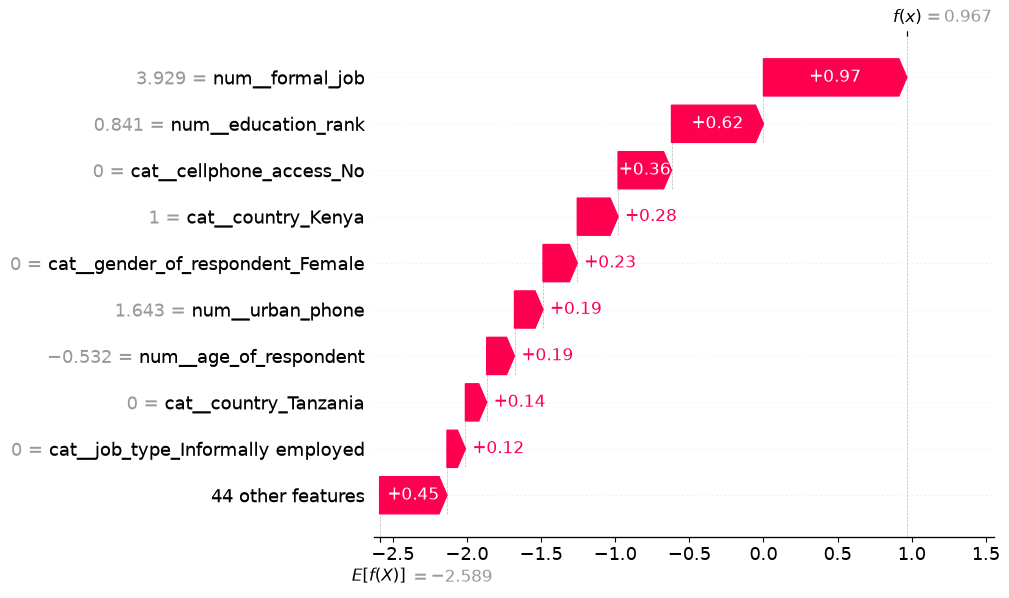

In [8]:
# Q11.3 : une personne (la première du test au-dessus du seuil et réellement bancarisée)
i = int(np.flatnonzero((y_pred == 1) & (y_test.values == 1))[0])
print(X_test.iloc[i].to_string())
print(f"\nProbabilité calibrée : {p_test[i]:.3f} | log-odds non calibrés : {sv.base_values[i] + sv.values[i].sum():.3f}"
      f" (valeur de base {sv.base_values[i]:.3f})")
shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.savefig(FIGURES / "06_shap_waterfall.png", dpi=120, bbox_inches="tight"); plt.show()

Q11.3 — Personne choisie : homme de 30 ans au Kenya, en ville, avec un téléphone, vivant seul, études secondaires, salarié du privé. Probabilité : 74 % (la moyenne est 14 %). Ce qui fait monter le score : l'emploi formel, l'éducation, le téléphone, le Kenya.

Pour un agent de terrain : « Cette personne a un emploi salarié et a fait des études secondaires, ce sont les deux signes les plus liés à un compte bancaire. Elle vit en ville au Kenya et a un téléphone. Il y a environ 3 chances sur 4 qu'elle ait un compte : à contacter en priorité. »

In [9]:
# Q11.4 : le genre
gidx = [j for j, c in enumerate(noms) if "gender" in c]
print("|SHAP| moyen des colonnes de genre :", np.abs(sv.values[:, gidx]).sum(1).mean().round(4),
      "| rang :", int(comp.loc["gender_of_respondent", "rang SHAP"]), "sur", len(comp))
g = X_test["gender_of_respondent"]
pd.DataFrame({sexe: {"effectif": int((g == sexe).sum()),
                     "prévalence": y_test[g == sexe].mean(),
                     "recall": recall_score(y_test[g == sexe], y_pred[g == sexe]),
                     "taux contacté": y_pred[g == sexe].mean(),
                     "proba moyenne": p_test[g == sexe].mean()}
              for sexe in ("Female", "Male")}).T.round(3)

|SHAP| moyen des colonnes de genre : 0.1986 | rang : 6 sur 11


,effectif,prévalence,recall,taux contacté,proba moyenne
Female,2792.0,0.109,0.849,0.303,0.111
Male,1913.0,0.187,0.905,0.527,0.194


Q11.4 — Oui, le genre joue un peu (6ᵉ en SHAP, 7ᵉ en permutation). Sur le test :

| | Effectif | Prévalence | Recall | Taux contacté |
|---|---|---|---|---|
| Femmes | 2 792 | 10,9 % | 0,849 | 30 % |
| Hommes | 1 913 | 18,7 % | 0,905 | 53 % |

Le modèle retrouve moins bien les femmes bancarisées (85 % contre 91 %). Je retirerais le genre du modèle : il apporte très peu (0,010 de PR-AUC) et il désavantage les femmes, ce qui va contre l'inclusion financière. Je le garderais seulement pour vérifier l'équité entre hommes et femmes.

Q11.5 — Non. Le modèle montre seulement que les gens avec un téléphone ont plus souvent un compte. Ça ne veut pas dire que le téléphone en est la cause : le revenu, l'emploi ou l'éducation peuvent expliquer les deux. Pour le savoir, il faudrait une expérience (donner des téléphones au hasard et regarder ce qui se passe).